# Дрва на одлучување и ансамбли

In [32]:
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
import numpy as np
from sklearn.datasets import make_gaussian_quantiles
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier

### Генерирање работно податочно множество
Со цел да се запознаеме со општите карактеристики на моделите ќе генерираме едно подааточно множество на класификација со две класи и две карактеристики.

In [33]:
# Construct dataset
X1, y1 = make_gaussian_quantiles(cov=10,
                                 n_samples=200, n_features=2,
                                 n_classes=2, random_state=1)
X2, y2 = make_gaussian_quantiles(mean=(5, 5), cov=10,
                                 n_samples=300, n_features=2,
                                 n_classes=2, random_state=1)
X = np.concatenate((X1, X2))
y = np.concatenate((y1, - y2 + 1))

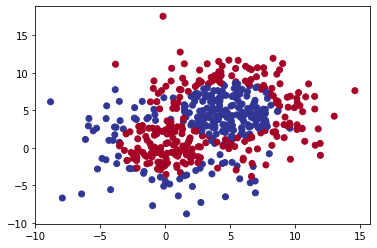

In [34]:
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu)

## Дрво на одлучување (Decision Tree)
Претставува модел на учење со надзор кој може да се користи за класификација или регресија. Моделот применува if-else метода која што го дели податочното множество на помали подмножества се' додека не се намалат на големина **min_samples_split** или бројот на поделби не надмине **max_depth**. Со помош нa if-else методата, множеството се дели врз основа избрана гранична вредност според избрана карактеристика од податочното множество. Изборот на карактеристиките и граничната вредност, за поделба на множеството, се врши според тоа која од нив носи најмногу информација (information gain). Пристапот на оваа if-else метода може да се визуелизира со помош на едно дрво на одлучување каде секоја поделба е претставена со гранење на дрвото. Една од главните предности на овој модел е тоа што не претставува црна кутија (black box). Секоја одлука на моделот може да се визуелизира и да се види зошто истата е направена. Моделите базирани на дрва на одлучување исто така немаат потреба од скалирање на податочното множество бидејќи не се користи конвенционална функција на цена при тренирање.

|Предности|Недостатоци|
|---|---|
|Моделот не претставува црна кутија (black box)|Тежнее кон overfitting за големи длабочини|    
|Моќен при наоѓање на нелинеарни зависности| Бара внимателно нагодување на параметрите за тренирање|
|Нема потреба од скалирање на податочното множество||

Клучни параметри:
* **max_depth:** Максимална длабочина која може да ја достигне дрвото при негово гранење. Опсег на вредности: **[1, inf)**
* **min_samples_split:** Минимален број на податоци потребни за гранењето на дрвото да продолжи. Опсег на вредности: **[2, m(зависи од големина на множество)]**
* **criterion:** Метода за пресметка на информацијата што ја носи карактеристиката при нејзин избор за поделба. Вредности: ['gini', 'entropy', 'log_loss']
* **min_samples_leaf:** Минимален број на податочни точки во еден лист, каде листот претставува крајниот јазол на дрвото (најдлабоката точка на гранење).

### Влијание на длабочината на дрвото (max_depth)

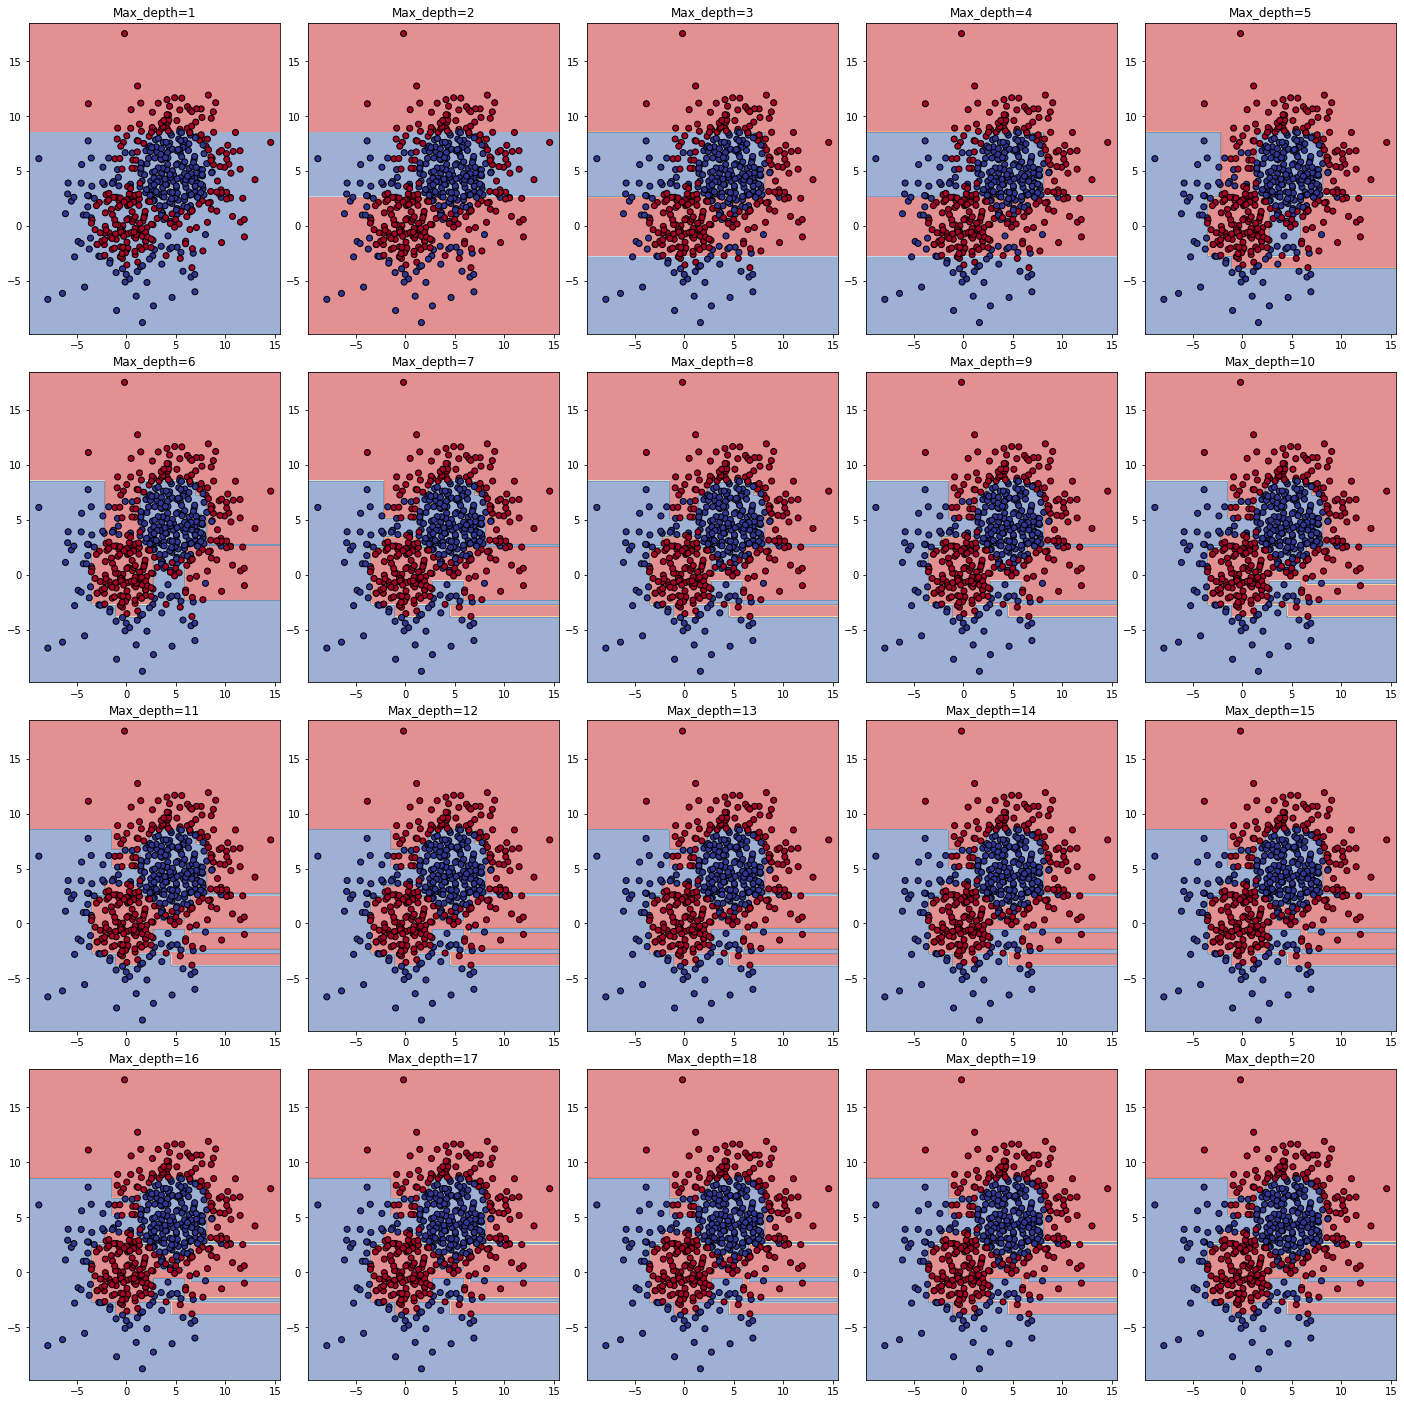

In [35]:
plt.figure(figsize=(20, 20))
depths = np.arange(0, 20) + 1

for i, depth in enumerate(depths):
    dtree = DecisionTreeClassifier(max_depth=depth, min_samples_split=2, random_state=0)
    dtree.fit(X, y)

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 0.1))
    plt.tight_layout(h_pad=0.5, w_pad=0.5, pad=2.5)

    Z = dtree.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    plt.subplot(depths.shape[0]//5, 5, i + 1)
    plt.contourf(xx, yy, Z, cmap=plt.cm.RdYlBu, alpha=0.5)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu, edgecolor='black')
    plt.title(f"Max_depth={depth}")

Може да се забележи дека колку подлабоко дрвото на одлучување се тренира, толку повеќе моделот тежнее да следи покомплексни зависности. Треба да се внимава овој параметар да не е преголем поради проблем на overfitting, како во последните 14 графици.

### Влијание на минималниот број на податоци за разгранување на дрвото (min_samples_split)

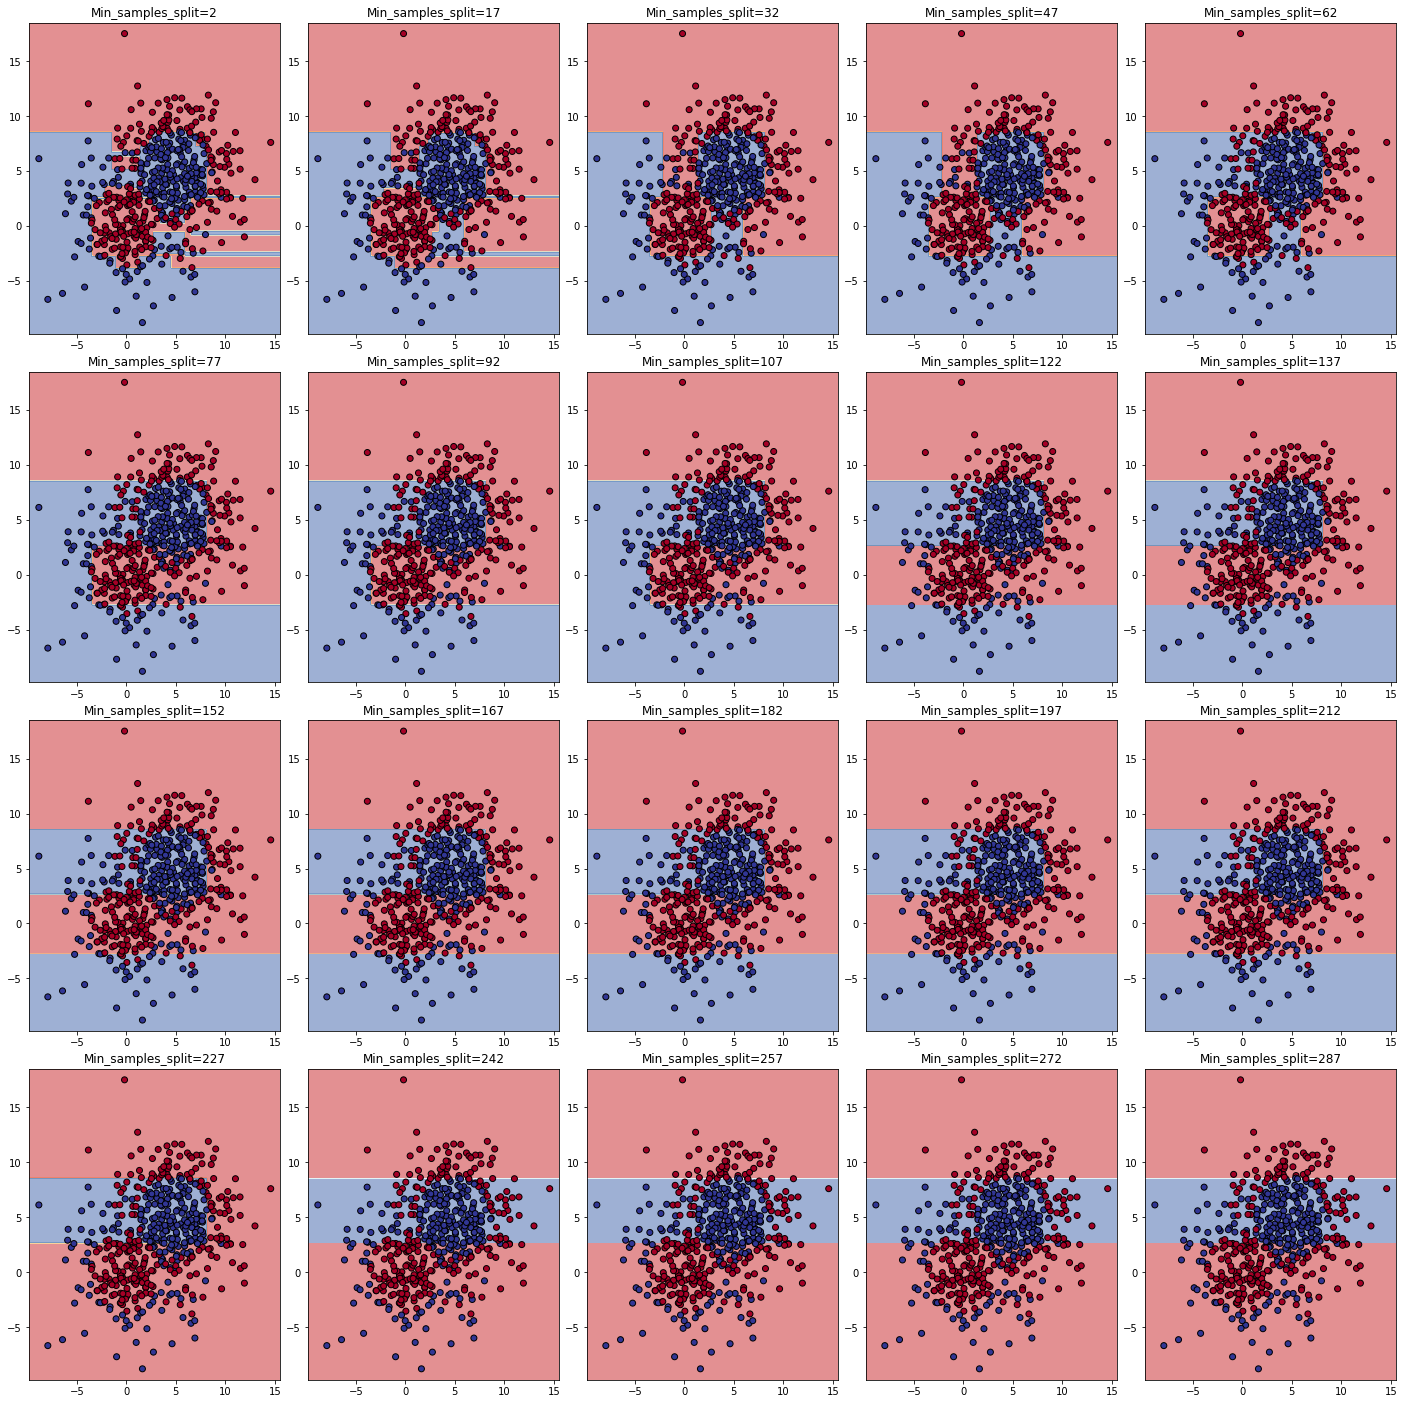

In [36]:
plt.figure(figsize=(20, 20))
splits = np.arange(0, 300, 15) + 2

for i, split in enumerate(splits):
    dtree = DecisionTreeClassifier(max_depth=10, min_samples_split=split, random_state=0)
    dtree.fit(X, y)

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 0.1))
    plt.tight_layout(h_pad=0.5, w_pad=0.5, pad=2.5)

    Z = dtree.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    plt.subplot(splits.shape[0]//5, 5, i + 1)
    plt.contourf(xx, yy, Z, cmap=plt.cm.RdYlBu, alpha=0.5)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu, edgecolor='black')
    plt.title(f"Min_samples_split={split}")

Може да се забележи дека колку поголема вредност имаме за овој параметар, толку подобро моделот генерализира при предвидување. Потребно е да се внимава оваа вредност да не е преголема поради проблем на underfitting како во последните 5 графици.

## Random Forest
Еден од главните проблеми на Decision Tree моделот е тоа што тежнее да прави overfitting. Овој проблем многу лесно може да се надмине со помош на ансамбл од повеќе дрва на одлучување. Еден модел кој претставува ансамбл од повеќе дрва на одлучување е Random Forest. Random Forest, всушност користи множество на повеќе дрва на одлучување кои се тренирани на различни делови од податочнито множество каде се бираат различни карактеристики по случаен избор. Крајната одлука претставува сублимат од одлуката на секое индивидуално дрво. овој пристап помага со цел да се надмине проблемот на overfitting.

|Предности|Недостатоци|
|---|---|
|Моделот претставува црна кутија (black box)|Робусен модел по однос на overfitting|    
|Моќен при наоѓање на нелинеарни зависности| Бара внимателно нагодување на параметрите за тренирање|
|Нема потреба од скалирање на податочното множество||

Клучни параметри:
* **n_estimators:** Број на дрва кои ќе се тренираат. Опсег на вредности: **[2, inf)**
* Сите останати параметри важат исто како и кај моделот на дрво на одлучување.
### Влијание на бројот на дрва (n_estimators) при плитки длабочини на индивидуалното дрво

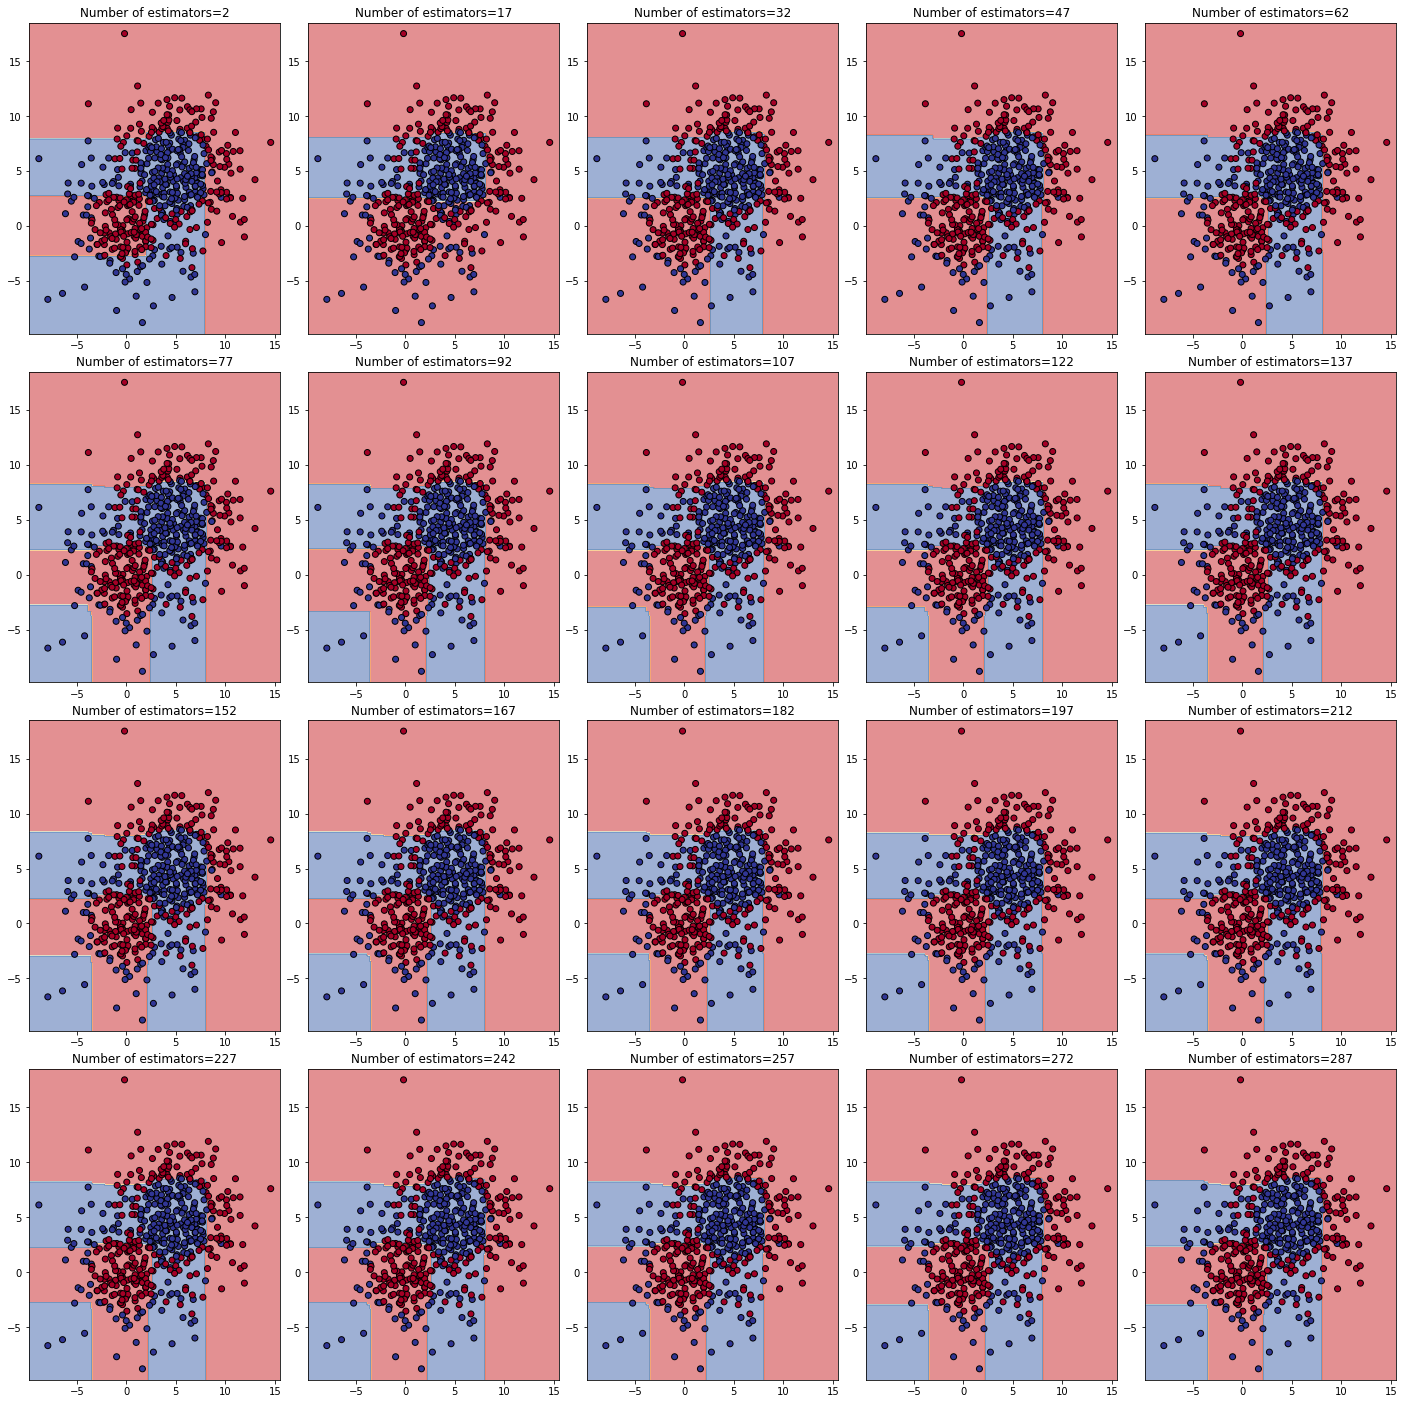

In [37]:
plt.figure(figsize=(20, 20))
nrs = np.arange(0, 300, 15) + 2

for i, nr in enumerate(nrs):
    dtree = RandomForestClassifier(n_estimators=nr, max_depth=2, min_samples_split=2, random_state=0)
    dtree.fit(X, y)

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 0.1))
    plt.tight_layout(h_pad=0.5, w_pad=0.5, pad=2.5)

    Z = dtree.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    plt.subplot(nrs.shape[0]//5, 5, i + 1)
    plt.contourf(xx, yy, Z, cmap=plt.cm.RdYlBu, alpha=0.5)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu, edgecolor='black')
    plt.title(f"Number of estimators={nr}")

Може да се забележи дека бројот на дрва нема големо влијание во случаи кога индивидуалното дрво е плитко при тренирање.

### Влијание на бројот на дрва (n_estimators) при големи длабочини на индивидуалното дрво

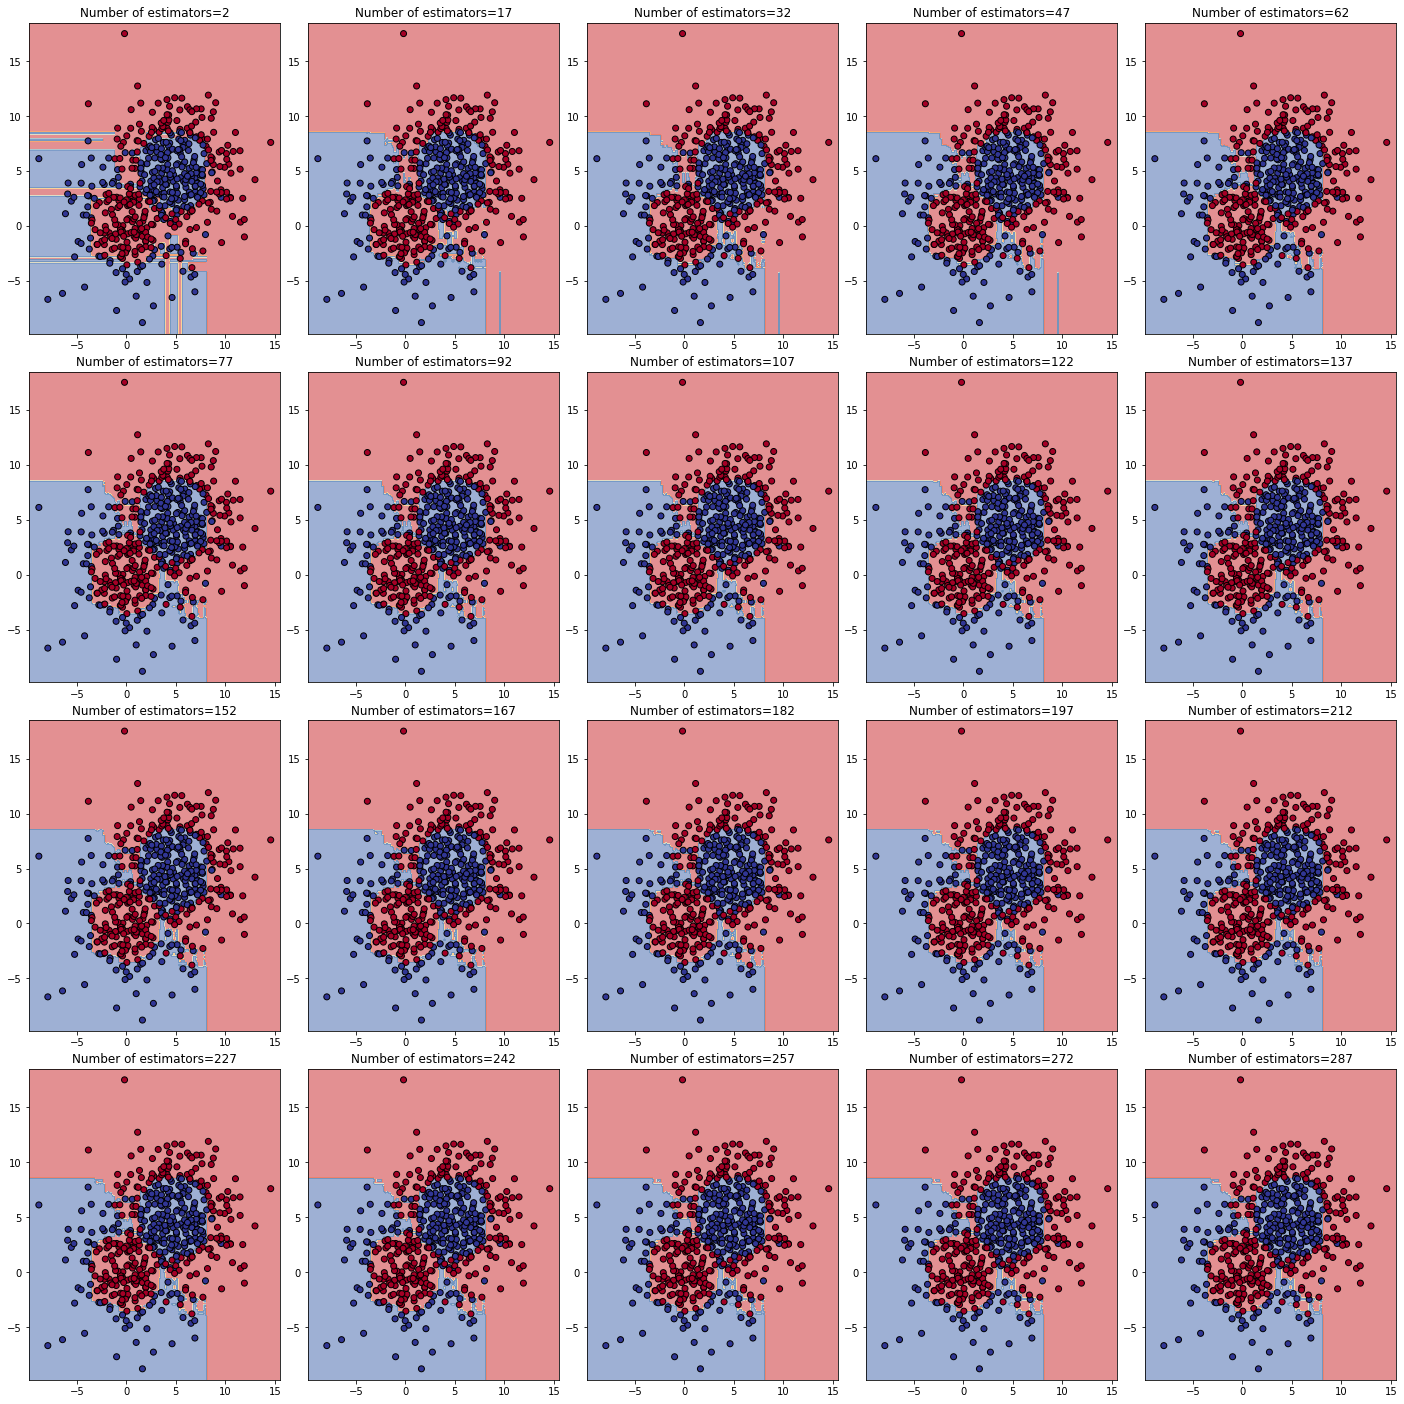

In [38]:
plt.figure(figsize=(20, 20))
nrs = np.arange(0, 300, 15) + 2

for i, nr in enumerate(nrs):
    dtree = RandomForestClassifier(n_estimators=nr, max_depth=None, min_samples_split=2, random_state=0)
    dtree.fit(X, y)

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 0.1))
    plt.tight_layout(h_pad=0.5, w_pad=0.5, pad=2.5)

    Z = dtree.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    plt.subplot(nrs.shape[0]//5, 5, i + 1)
    plt.contourf(xx, yy, Z, cmap=plt.cm.RdYlBu, alpha=0.5)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu, edgecolor='black')
    plt.title(f"Number of estimators={nr}")

Може да се забележи дека повеќе дрва на одлучување во ансамблот, помагаат да се намали проблемот на overfitting во случај кога индивидуалното дрво е длабоко.

## Adaboost
Adaboost и други gradient boosting методи применуваат ансамбли од повеќе слаби модели со цел да се изгради еден комплексен модел. Слабите модели најчесто имаат проблем на underfitting кога се користат индивидуално. Идејата на Adaboost е да се направи ансамбл од повеќе плитки дрва на одлучување (најчесто длабочина 1) со чија помош ќе се изгради комплексен модел. За разлика од Random Forest каде секое дрво има подеднаков глас при одлучувањето, Adaboost доделува тежини за одлуките на секое дрво индивидуално, во зависност од неговата способност. При градење на ансамблот од дрва на одлучување, секое ново дрво на одлучување се креира во зависност од грешките направени од предходното. Од тука доаѓа и терминот 'boosting'. За разлика од Random Forest, каде секое индивидуално дрво се гради врз основа на случаен избор, Adaboost го гради секое ново индивидуално дрво со цел да го подобри моделот на предвидување.

|Предности|Недостатоци|
|---|---|
|Моделот претставува црна кутија (black box)|Полош од Random Forest но подобар од Decision Tree по однос на overfitting|    
|Моќен при наоѓање на нелинеарни зависности (најчесто подобар од Random Forest & Decision Tree)| Бара внимателно нагодување на параметрите за тренирање|
|Нема потреба од скалирање на податочното множество||

Клучни параметри:
* **estimator:** Индивидуалниот модел од кој ќе се гради ансамблот. Доколку не се додели модел, автоматски се користи DecisionTreeClassifier.
* **n_estimators:** Максимален број на модели за да запре процесот на тренирање. Опсег на вредности: **[1, inf)**
* **learning_rate:** Стапка на учење за колку да се подобри секој нареден модел, во споредба со предходниот. Овој параметар директно зависи од **n_estimators** параметарот. Доколку **n_estimators** има голема вредност, тогаш се препорачува мала вредност за **learning_rate**. Во спротивно, доколку **n_estimators** е мала вредност тогаш се препорачува поголема вредност за **learning_rate**. Опсег на вредности: **(0, inf)**
### Влијание на бројот на класификатори (n_estimators)

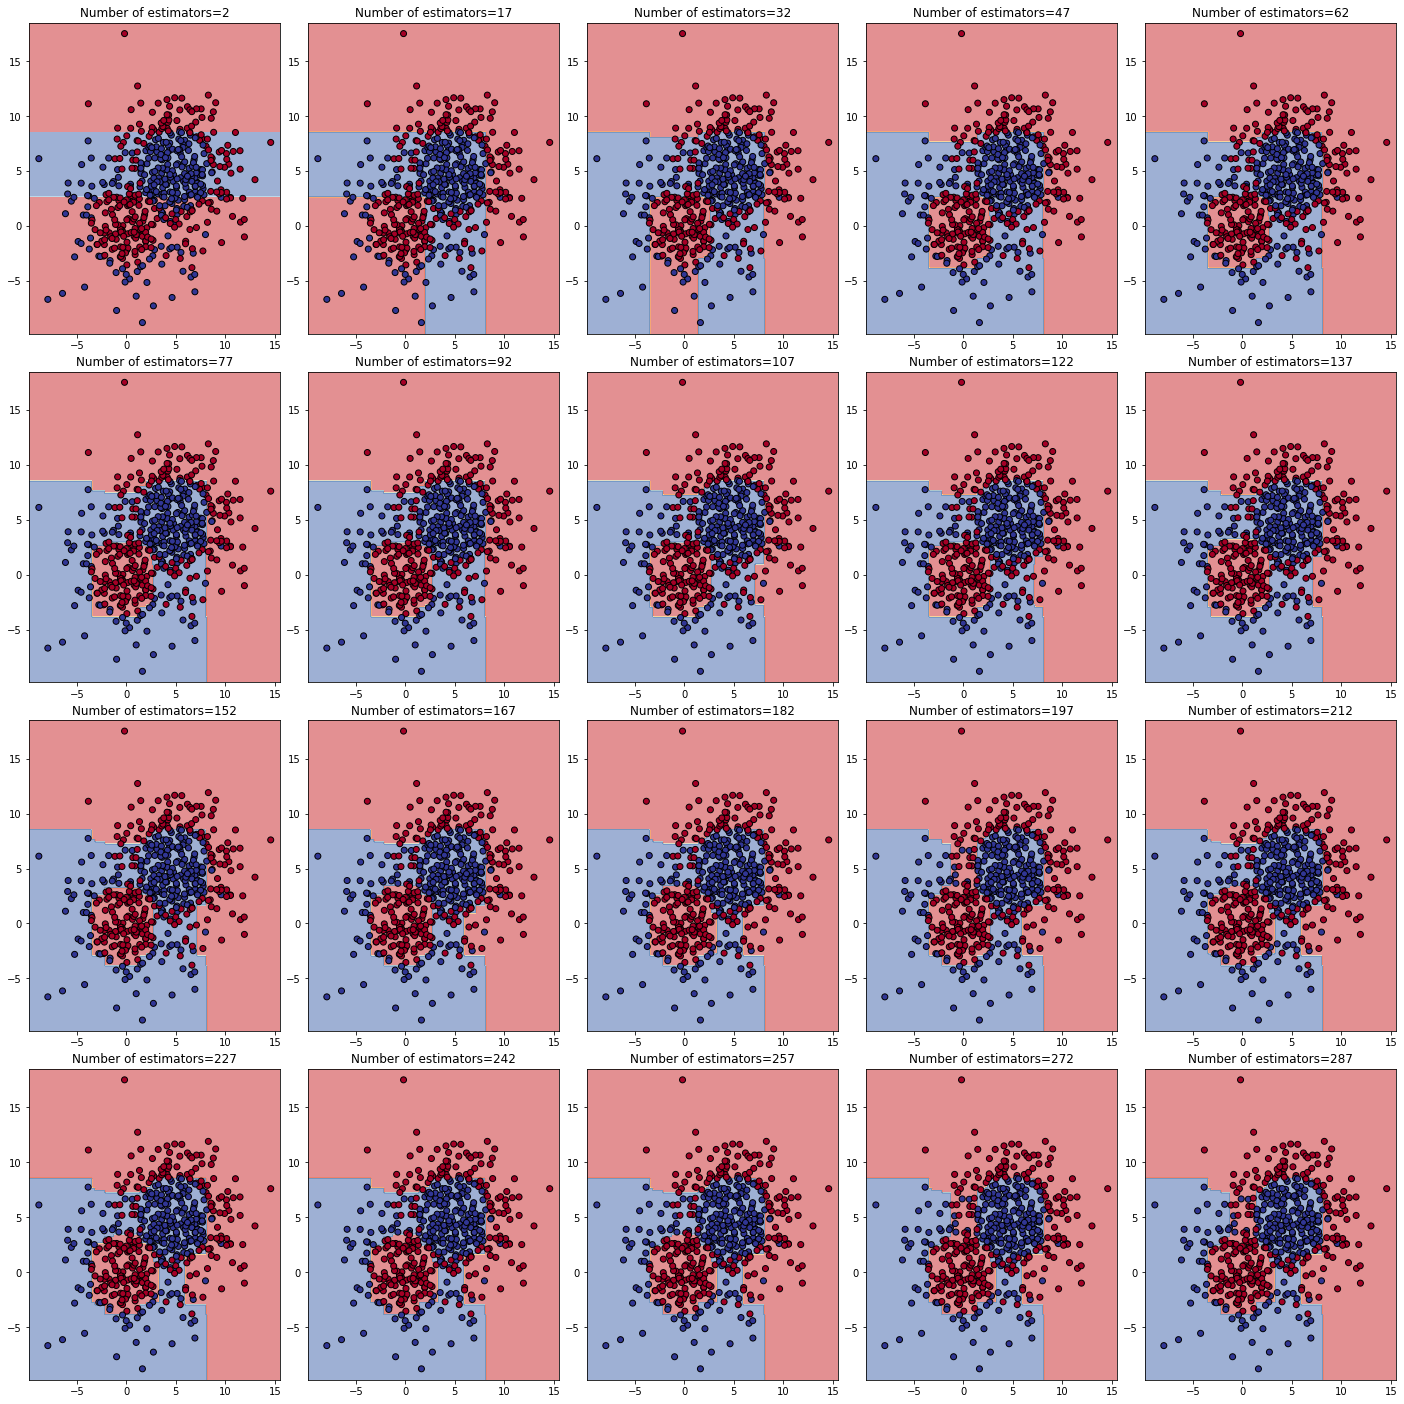

In [39]:
plt.figure(figsize=(20, 20))
nrs = np.arange(0, 300, 15) + 2

for i, nr in enumerate(nrs):
    dtree = AdaBoostClassifier(DecisionTreeClassifier(max_depth=2, min_samples_split=2), n_estimators=nr, learning_rate=0.1, random_state=0, algorithm='SAMME')
    dtree.fit(X, y)

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 0.1))
    plt.tight_layout(h_pad=0.5, w_pad=0.5, pad=2.5)

    Z = dtree.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    plt.subplot(nrs.shape[0]//5, 5, i + 1)
    plt.contourf(xx, yy, Z, cmap=plt.cm.RdYlBu, alpha=0.5)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu, edgecolor='black')
    plt.title(f"Number of estimators={nr}")

Може да се забележи дека зголемувњето на бројот на модели го подобрува предвидувањето на главниот модел. Сепак ова доаѓа на сметка на подолго време на тренирање.

### Влијание на стапката на учење (learning_rate)

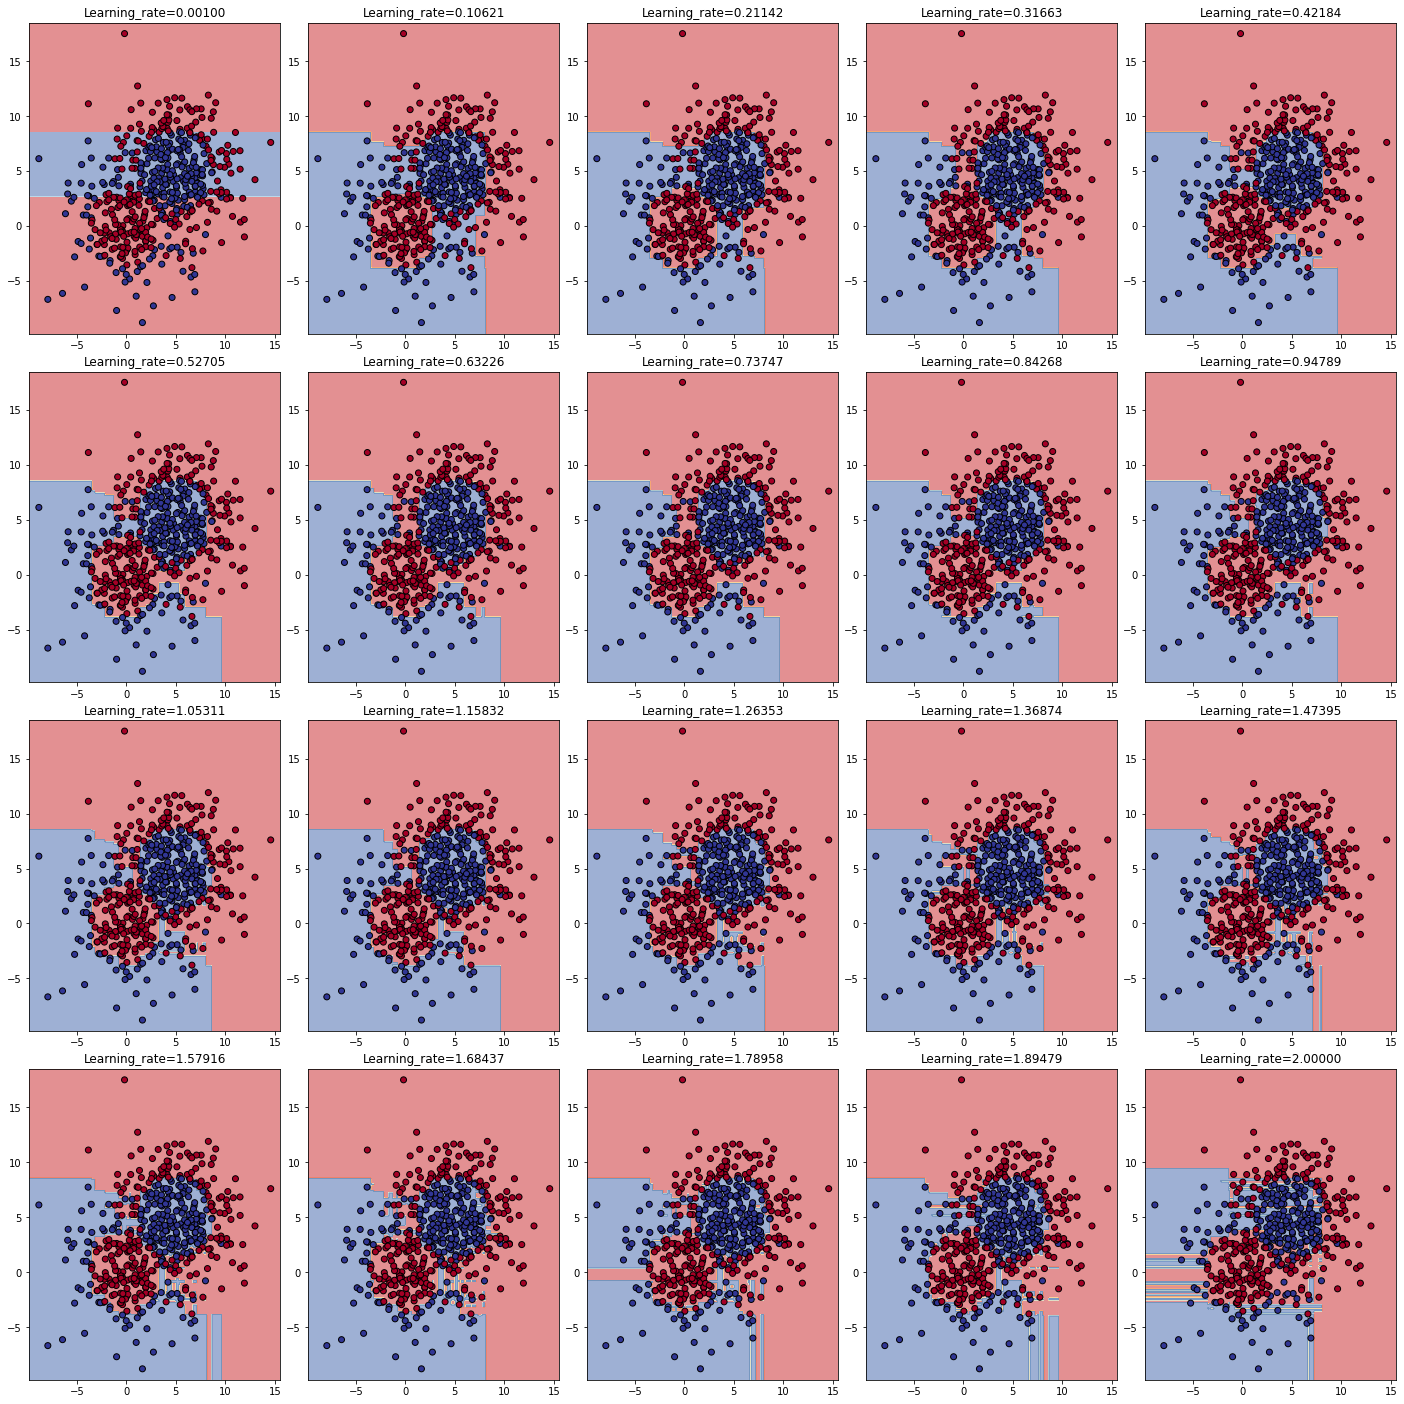

In [40]:
plt.figure(figsize=(20, 20))
lrates = np.linspace(1e-3, 2, 20)

for i, lr in enumerate(lrates):
    dtree = AdaBoostClassifier(DecisionTreeClassifier(max_depth=2, min_samples_split=2), n_estimators=100, learning_rate=lr, random_state=0, algorithm='SAMME')
    dtree.fit(X, y)

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 0.1))
    plt.tight_layout(h_pad=0.5, w_pad=0.5, pad=2.5)

    Z = dtree.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    plt.subplot(nrs.shape[0]//5, 5, i + 1)
    plt.contourf(xx, yy, Z, cmap=plt.cm.RdYlBu, alpha=0.5)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu, edgecolor='black')
    plt.title("Learning_rate=%.5f" % lr)

Може да се забележи дека мала стапка на учење води кон проблем на underfitting додека преголема стапка на учење води кон overfitting.

# Предвидување на преживеани во Titanic податочното множество

Податоците за преживеаните патници од бродот Titanic ќе ги искористиме за да изградиме модел кој ќе предвидува кој има поголема веројатност да преживее.

Податочното множество ги содржи следните колони:

* **PassengerId:** Идентификациски број на патникот
* **Pclass:** Патничка класа
* **Name:** Име на патникот
* **Sex:** Пол на патникот
* **Age:** Возраст на патникот
* **SibSp:** Број на браќа-сестри/брачен другар кои што се со патникот на бродот
* **Parch:** Број на родители/деца кои што се со патникот на бродот
* **Ticket:** Број на билетот
* **fare:** Цена на билетот
* **Cabin:** Број на кабина во која бил сместен патникот
* **Embarked:** Пристаниште каде се качил патникот
* **Survival:** Дали преживеал патникот

Дополнителни податоци:
Pclass: Алтернатива за социо-економската состојба на патникот
1st = Прва класа
2nd = Средна класа
3rd = Ниска класа

age: Возраста може да биде и рацинален број за патници помали од 1 година

sibsp: Роднинските врска можат да бидат претставени на следниот начин...
Sibling = брат, сестра, полубрат, полусестра
Spouse = Сопруг, сопруга (верениците се игнорирани)

parch: Роднинските врска можат да бидат претставени на следниот начин
Parent = мајка, татко
Child = ќерка, син, полусин, полуќерка

Некои деца патувале само со дадилка, последователно parch=0 за нив.

### Користени библиотеки

In [42]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score
from sklearn.tree import DecisionTreeClassifier
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn import tree

In [43]:
data = pd.read_csv('titanic_train.csv', 
                   dtype={'Pclass': 'uint8', 'Age': 'float16', 'SibSp': 'uint8', 'Parch': 'uint8', 'Survived': 'bool'}, 
                   usecols=range(1, 12))

### Остранување на NaN 

In [44]:
data.dropna(axis=0, subset=['Embarked'],  inplace=True)

data.drop(columns='Cabin', inplace=True)

means = data.groupby(['Sex', 'Pclass'])['Age'].mean()
for sex, pclass in means.index:
    data.loc[data['Age'].isnull() & (data['Sex'] == sex) & (data['Pclass'] == pclass), 'Age'] = means[sex][pclass]

### Специфичности кај дрвата на одлучување од аспект на категорички карактеристики

Дрвата на одлучување можат да работат со редоследни(ordinal) категорички карактеристики. Поради тоа, нема потреба од one-hot-encoding за патничката класа бидејќи повисок број означува повисока цена на билет, позначаен статус, кабина која е поблиску до палубата, итн.

Дрвата на одлучување можат да дадат лоши резултати кај номиналните категорички карактеристики доколку не се применува one-hot-encoding. При голем број на вакви карактеристики може да настане проблем во предвидувањето.

**Доколку корисникот не е сигурен дали категоричката карактеристика е ординална или номинална, тогаш секако може да примени one-hot-encoding на сметка на побавно тренирање.**

In [45]:
data['Sex'] = data['Sex'].map({'male': 0, 'female': 1})

In [46]:
data = pd.concat([data, 
                  pd.get_dummies(data['Embarked'], prefix='Embarked', drop_first=True)], axis=1)

In [47]:
data.drop(columns='Embarked', inplace=True)

### Поделба на множеството

In [48]:
X = data.drop(columns=['Name', 'Survived', 'Ticket'])
y = data['Survived']

In [49]:
X_train, X_test, y_train, y_test = train_test_split(X.to_numpy(), y.to_numpy(), test_size = 1/3, random_state=0)

## Градење на модел на дрво на одлучување

### Тренирајте модел на дрво на одлучување со следните параметри

* max_depth=3
* min_samples_split=12
* random_state=0

Променливата во која ќе се смести моделот да се именува како "model".

**помош: DecisionTreeClassifier()**

In [50]:
model = DecisionTreeClassifier(max_depth=3, min_samples_split=12)
model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=3, min_samples_split=12)

### Направете f1_score евалуација врз множеството за тестирање

In [51]:
predicts = model.predict(X_test)
print(classification_report(y_test, predicts))

              precision    recall  f1-score   support

       False       0.80      0.86      0.83       177
        True       0.76      0.68      0.72       120

    accuracy                           0.78       297
   macro avg       0.78      0.77      0.77       297
weighted avg       0.78      0.78      0.78       297



### Визуелизација на дрвото

Една од главните предности на користење на еден модел на дрво на одлучување е тоа што моделот не е кутија. Имено, одлуката на моделот за секоја податочна точка може да се анализира зошто истата била направена. Ова помага при анализа на моделот да се утврди зошто истиот згрешил во случај на грешка.

Во следната ќелија ќе го визуелизираме дрвото според кој горе истренираниот модел одлучување дали еден патник преживеал или не.

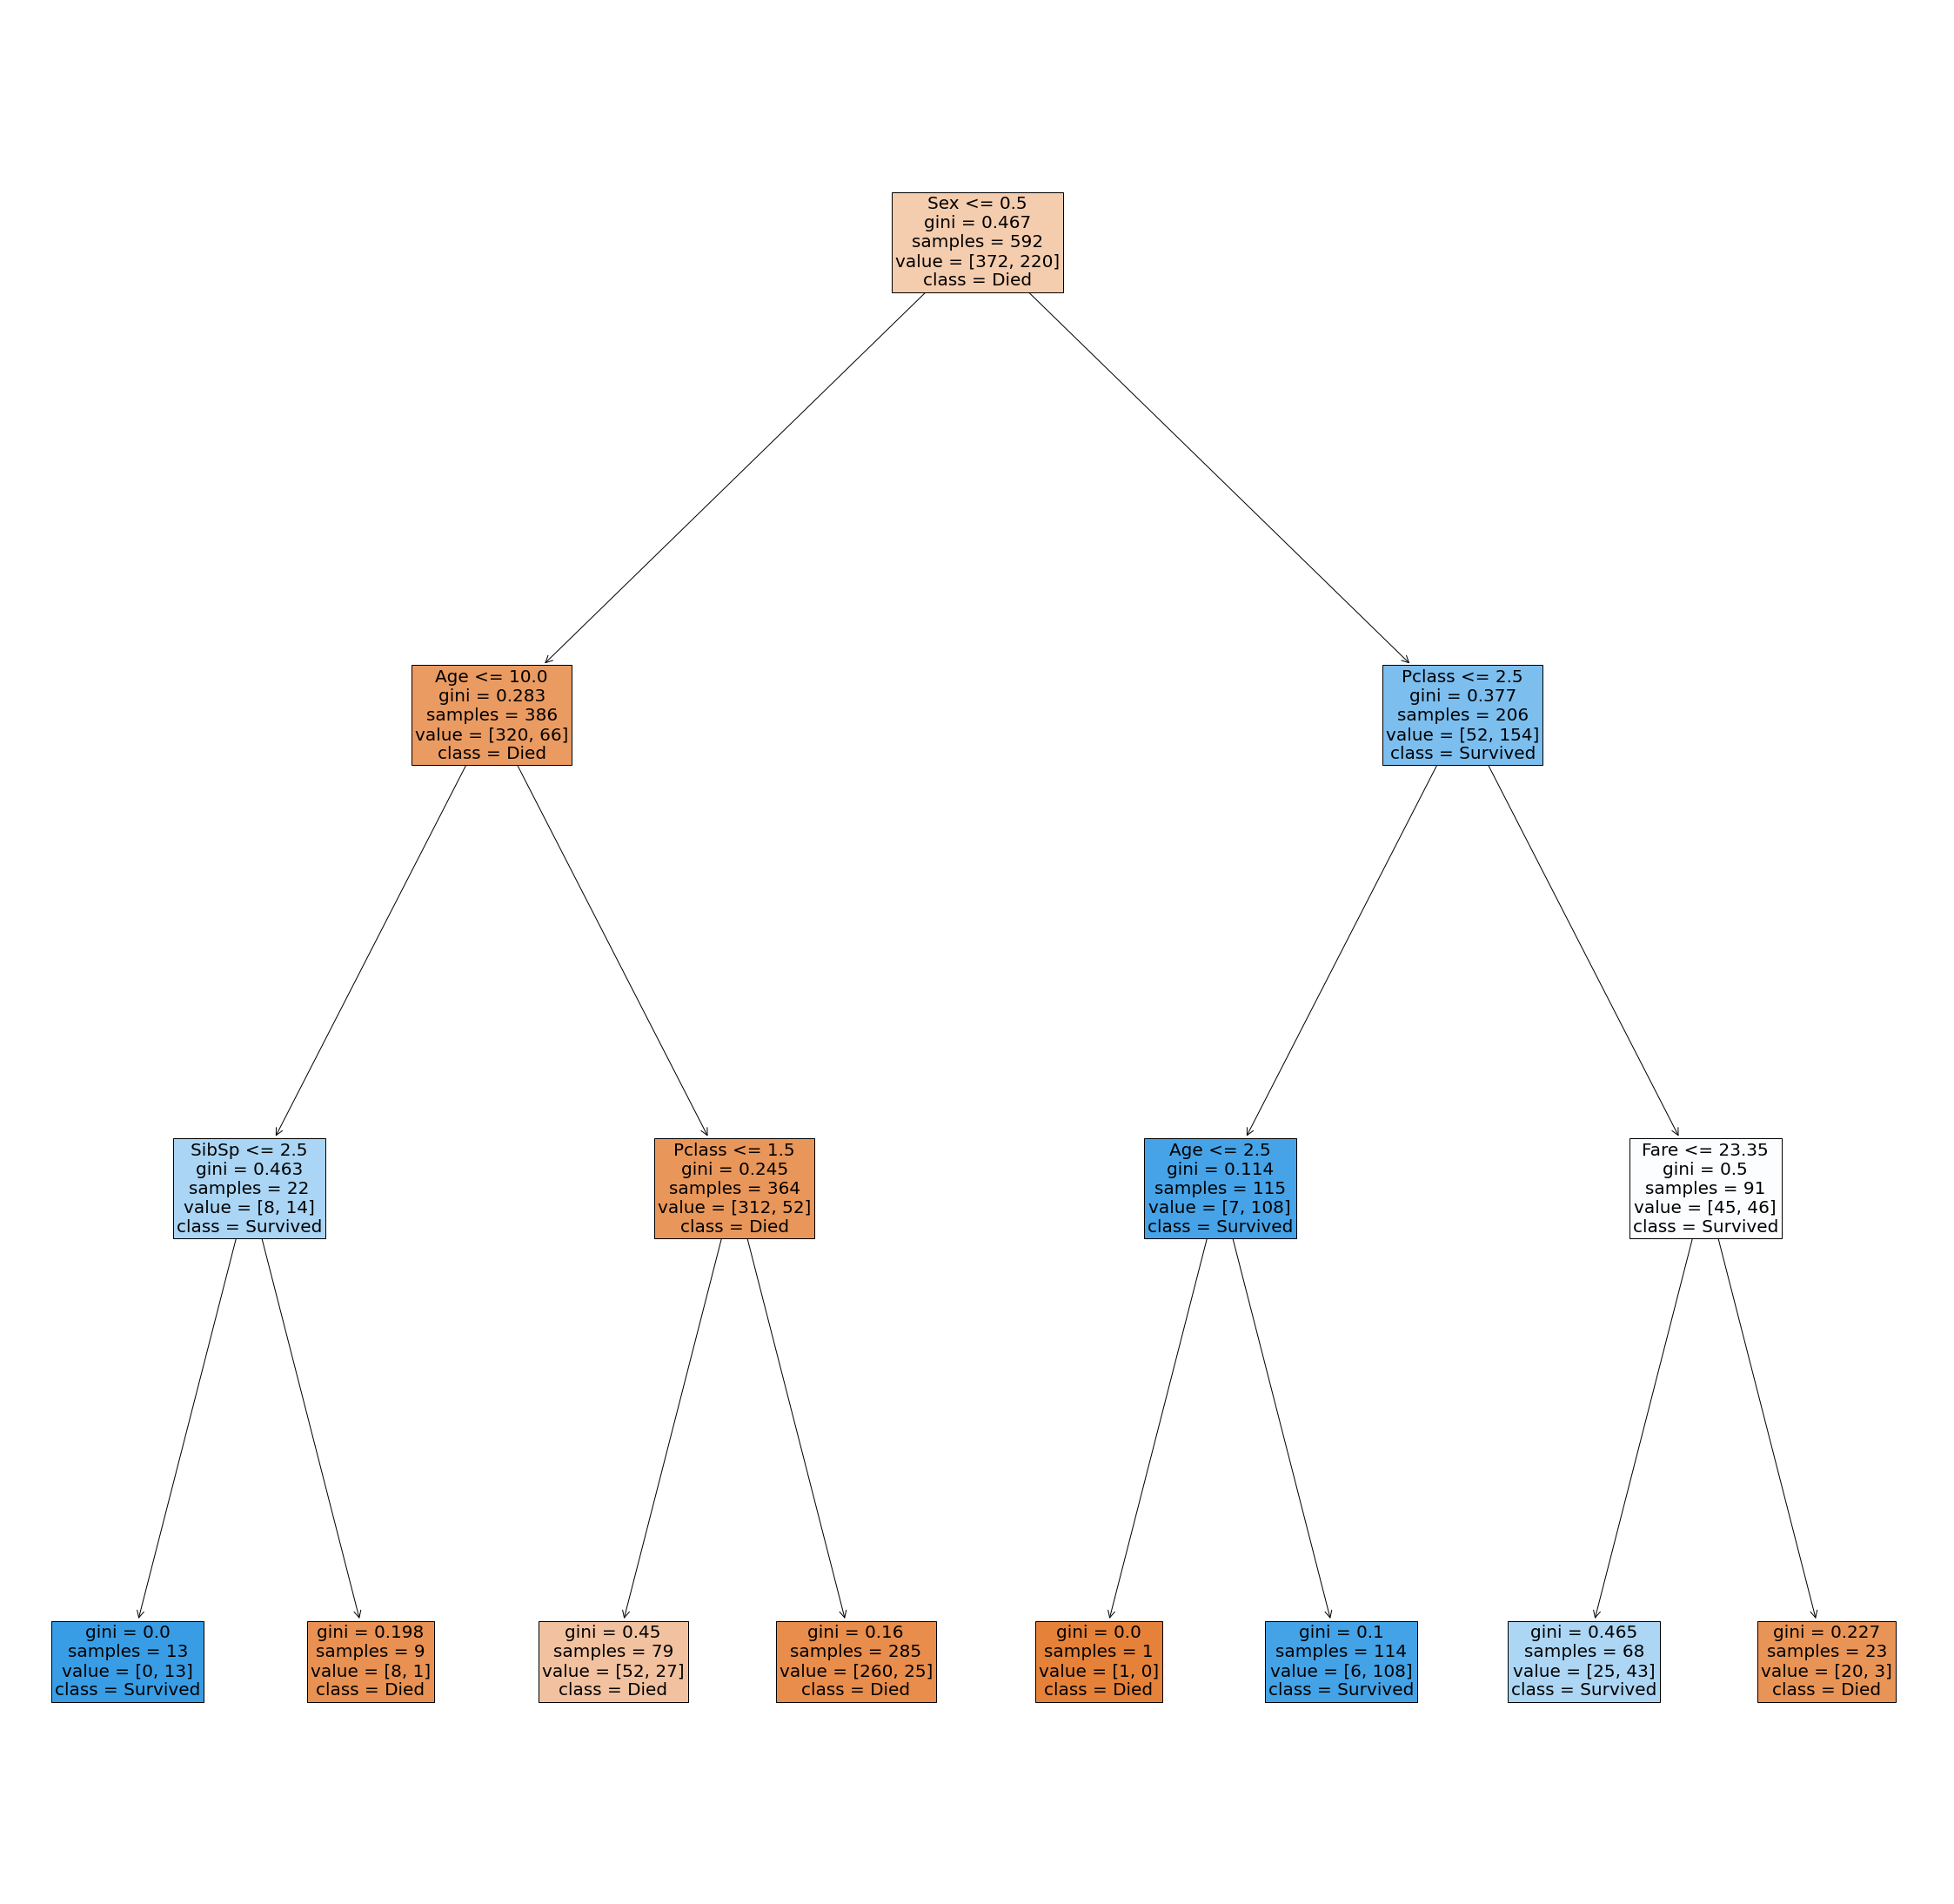

In [52]:
plt.figure(figsize=(40, 40))
tree.plot_tree(model, fontsize=20, feature_names=X.columns, filled=True, class_names=['Died', 'Survived'])
plt.show()
# Left -> True; Right >- False

Следните заклучоци може да се извлечат од визуелизацијата:
1. Мнозинството од машките патници на возраст поголема од 10 години, без разлика на патничката класа, дрвото ќе ги предвидува како загинати.
2. Машките патниците на возраст помала од 10 години и број на роднини помал од 2.5, моделот ќе ги предвидува како преживеани.
3. Мнозинството од женските патници ќе ги предвидува како преживеани, со исклучок на оние кои биле во трета патничка класа со поскапи билети од 23.35.

# Градење на AdaBoost модел и концепт на Pipeline и негова имплементација со GridSearch
Многу често има потреба од примена на GridSearch врз повеќе функции кои се применуваат на податочното множество како: скалирање, PCA(), тренирање, итн. Конкретно, во овој случај ја имаме следната низа од постапки:

1. **Примена на PCA:** каде параметарот n_components подлежи на нагодување
2. **Тренирање на AdaBoost модел:** каде низа параметри како [max_depth, min_samples_split, n_estimators, learning_rate] подлежат на нагодување

За да можеме да ги вклучиме параметрите на PCA во Gridsearch, ќе примениме концепт на Pipeline, дефиниран од sklearn библиотеката. Pipeline класата од sklearn овозможува да се извршуваат низа од повеќе постапки врз податочното множество со извршување на една функција како fit() или fit_transform(). Ова ќе ни овозможи Pipeline објект да дадеме на влез на GridSearch. Во конкретниот пример, двете постапки од погоре можеме да ги извршиме само со една fit() функција, наместо посебно да применуваме PCA() и да тренираме AdaBoost() модел. На тој начин ќе можеме едновремено да примениме GridSearch и на PCA() и на AdaBoost(), за различни нивни параметри.

Понатамошно, бидејќи PCA не работи добро на категорички карактеристики, потребно е PCA да се извршува само на нумеричките. За таа намена ќе напишеме рачно изработена функција која на влез ќе го добива податочното множество, и низа од индекси кои ќе ги означуваат нумеричките карактеристики од истото податочно множество. Потоа оваа рачно изработена функција ќе ја вметнеме во Pipeline.

In [53]:
class customPCA(BaseEstimator, TransformerMixin):
    def __init__(self, n_components=None, svd_solver='auto', random_state=0, num_feat=[]):
        self.n_components = n_components
        self.svd_solver = svd_solver
        self.random_state = random_state
        self.pca = PCA(n_components=n_components, svd_solver=svd_solver, random_state=random_state)
        self.num_feat = num_feat
    
    def fit(self, X, y=None):
        self.pca.fit(X[:, self.num_feat])
        return self
    
    def transform(self, X, y=None):
        self.cat_feat = ~np.in1d(np.arange(0, X.shape[1]), self.num_feat)
        X_return = np.hstack((self.pca.transform(X[:, self.num_feat]), X[:, self.cat_feat]))
        return X_return

При декларирање на customPCA() објект ќе избереме за num_feat=[2, 3, 4, 5] кој ги дава индексите на нумеричките карактеристики. Во овој случај тоа се: [Age, SibSp, Parch, Fare].

## Градењe на Pipeline и спроведување на GridSearch според повеќе параметри од моделот и OCA

In [77]:
pipe = Pipeline([('pca', customPCA(num_feat=[2, 3, 4, 5])), ('ada', AdaBoostClassifier(DecisionTreeClassifier()))])
                
param_grid = {'ada__base_estimator__max_depth': [1, 3, 10], 
              'ada__base_estimator__min_samples_split': [2, 5], 
              'ada__n_estimators': [10, 200], 
              'ada__learning_rate': [1e-2, 0.1, 1], 
              'pca__n_components': [1, 2, 4]} 

grid = GridSearchCV(pipe, 
                    param_grid, 
                    scoring='f1', # избираме f1_score за евалуација на секој од моделите при gridsearch (небалансирано множество)
                    refit=True,
                    n_jobs=-1,
                    cv=5,
                    verbose=1)
cv_results = grid.fit(X_train,y_train)

Fitting 5 folds for each of 108 candidates, totalling 540 fits


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:    0.1s
[Parallel(n_jobs=-1)]: Done 220 tasks      | elapsed:   11.0s
[Parallel(n_jobs=-1)]: Done 470 tasks      | elapsed:   29.1s
[Parallel(n_jobs=-1)]: Done 540 out of 540 | elapsed:   34.7s finished


In [78]:
grid.best_params_

{'ada__base_estimator__max_depth': 1,
 'ada__base_estimator__min_samples_split': 2,
 'ada__learning_rate': 0.1,
 'ada__n_estimators': 200,
 'pca__n_components': 1}

Забележете дека GridSearch успеало да најде подобра комбинација на параметри за PCA кога 3 од основните компоненти се елиминирани наспроите 4-те.

In [79]:
cv_results.best_score_

0.7708501570059323

In [80]:
predicts = cv_results.predict(X_test)
print(classification_report(y_test, predicts))

              precision    recall  f1-score   support

       False       0.78      0.84      0.81       177
        True       0.73      0.65      0.69       120

    accuracy                           0.76       297
   macro avg       0.75      0.74      0.75       297
weighted avg       0.76      0.76      0.76       297



Може да се забележи дека AdaBoost моделот нагоден со помош на GridSearch извади за нијанса полоши резултати отколку обично дрво на одлучување со max_depth=3. Причината за ова е бидејќи проблемот е многу едноставен и покомплексен модел како AdaBoost не помага при предвидување на волку едноставен проблем.

# Изградете модел на RandomForest со помош на Pipeline и Gridsearch